# Step 5. Segment Profiling & Strategy

이 노트북은 Step 4에서 선택한 최종 clustering 결과를 바탕으로 각 고객 세그먼트의 행동 특성, 이탈률, 위험 신호, 고객 속성 분포를 해석하고 카드사 관점의 유지·재활성화 전략을 제안한다.

이 단계에서는 새로운 clustering을 수행하지 않는다. Step 4의 결과 파일을 불러온 뒤, cluster label을 profiling table에 붙여서 segment별 특징을 해석한다.

## 입력 파일

```text
data/analysis/clustering_results/09_selected_model.json
data/analysis/clustering_results/10_selected_cluster_labels.csv
data/analysis/clustering_results/11_df_cluster_input_used.csv
data/analysis/clustering_results/12_df_profile_table_used.csv
```

## 출력 폴더

```text
data/analysis/segment_profiling/
```

## 주요 산출물

- `final_segment_profiling_table.csv`: segment별 핵심 수치 요약
- `segment_strategy_table.csv`: segment별 해석 및 전략 제안
- `cluster_axis_profile_mean.csv`: segment별 행동 축 평균
- `01_cluster_profile_heatmap.png`: 행동 축 profile heatmap
- `02_attrition_rate_by_segment.png`: segment별 이탈률 그래프
- `03_segment_size_vs_attrition_bubble.html`: 고객 규모와 이탈률 bubble chart
- `04_high_risk_signal_by_segment.png`: segment별 high-risk signal 평균
- `categorical_distribution_long.csv`: 범주형 변수 분포 long table
- `README_segment_profiling.md`: 산출물 설명 문서

## 0. 실행 전 확인

이 노트북을 실행하기 전에 반드시 아래 노트북이 순서대로 실행되어 있어야 한다.

```text
1. notebooks/03_5_further_preprocessing.ipynb
2. notebooks/04_clustering_model_selection.ipynb
```

현재 프로젝트는 상대경로 기반으로 구성되어 있으므로, VS Code에서 프로젝트 루트 또는 `notebooks/` 폴더에서 실행해도 동작하도록 작성되어 있다.

In [7]:
# ============================================================
# Step 5. Segment Profiling & Strategy
# 기본 설정
# ============================================================

from pathlib import Path
import sys
import json
import shutil

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px


def find_project_root():
    current = Path.cwd().resolve()
    candidates = [current] + list(current.parents)
    for path in candidates:
        if (path / "src" / "common.py").exists() and (path / "data").exists():
            return path
    return current

ROOT = find_project_root()
sys.path.insert(0, str(ROOT))

from src.common import (
    read_csv_safely,
    configure_korean_font,
    get_plotly_layout,
    save_json,
    save_csv,
)

configure_korean_font(verbose=True)

CLUSTERING_RESULT_DIR = ROOT / "data" / "analysis" / "clustering_results"
OUTPUT_DIR = ROOT / "data" / "analysis" / "segment_profiling"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Input dir:", CLUSTERING_RESULT_DIR.relative_to(ROOT))
print("Output dir:", OUTPUT_DIR.relative_to(ROOT))

[font] Matplotlib Korean font: Malgun Gothic
Project root: C:\Users\user\Desktop\BankChurners-Customer-Segmentation
Input dir: data\analysis\clustering_results
Output dir: data\analysis\segment_profiling


## 1. Step 4 결과 파일 로드

Step 4에서 선택된 모델 정보, 선택 모델의 cluster label, clustering input, profiling table을 불러온다.

In [8]:
# ============================================================
# 1. Step 4 결과 파일 로드
# ============================================================

selected_model_path = CLUSTERING_RESULT_DIR / "09_selected_model.json"
selected_labels_path = CLUSTERING_RESULT_DIR / "10_selected_cluster_labels.csv"
df_cluster_path = CLUSTERING_RESULT_DIR / "11_df_cluster_input_used.csv"
df_profile_path = CLUSTERING_RESULT_DIR / "12_df_profile_table_used.csv"

required_files = [
    selected_model_path,
    selected_labels_path,
    df_cluster_path,
    df_profile_path,
]

missing_files = [p for p in required_files if not p.exists()]
if missing_files:
    raise FileNotFoundError(
        "Step 4 결과 파일이 없습니다. 먼저 04_clustering_model_selection.ipynb를 실행하세요."
        + ".join(str(p.relative_to(ROOT)) for p in missing_files)"
    )

with open(selected_model_path, "r", encoding="utf-8") as f:
    selected_model = json.load(f)

df_cluster = read_csv_safely(df_cluster_path)
df_profile = read_csv_safely(df_profile_path)
labels_df = read_csv_safely(selected_labels_path)

print("Selected model metadata:")
print(json.dumps(selected_model, ensure_ascii=False, indent=4))
print("df_cluster:", df_cluster.shape)
print("df_profile:", df_profile.shape)
print("labels_df:", labels_df.shape)

display(df_cluster.head())
display(df_profile.head())
display(labels_df.head())

Selected model metadata:
{
    "selected_key": "axis_6_without_capacity_KMeans_k6",
    "selected_algorithm": "KMeans",
    "selected_feature_set": "axis_6_without_capacity",
    "selected_k": 6,
    "selected_features": [
        "Activity_Score",
        "Decline_Risk_Score",
        "Inactivity_Score",
        "Relationship_Strength_Score",
        "Contact_Burden_Score",
        "Credit_Utilization_Score"
    ],
    "random_state": 42,
    "selection_reason": [
        "Credit_Capacity_Score를 제외해 고객 신용한도 규모보다 실제 이용 행동에 집중한다.",
        "K-Means는 해석 가능성이 높고 segment profiling 및 발표에 적합하다.",
        "k=6은 계획서의 예상 고객 세그먼트 수와 잘 맞는다.",
        "내부 지표, cluster size balance, 이탈률 차이, high-risk signal 차이, 해석 가능성을 종합적으로 고려하였다."
    ],
    "selected_metrics": {
        "silhouette": 0.1528579419025467,
        "davies_bouldin": 1.604652990896418,
        "calinski_harabasz": 1435.6826534389381,
        "min_cluster_ratio": 0.08689641552285968,
        "max_cluster_ratio": 0.21793226029426285,
  

,Row_ID,Activity_Score,Decline_Risk_Score,Inactivity_Score,Relationship_Strength_Score,Contact_Burden_Score,Credit_Capacity_Score,Credit_Utilization_Score
0,0,-1.376877,-3.875446,-1.327136,0.815920,0.492404,0.905210,-0.775882
1,1,-1.478682,-4.415003,-1.327136,1.717721,-0.411616,0.444695,-0.616276
2,2,-1.465391,-4.415003,-1.327136,0.092026,-2.219655,-0.499786,-0.997155
3,3,-1.838587,-4.085577,1.641478,-0.542916,-1.315636,-0.533199,1.759686
4,4,-1.946479,-4.415003,-1.327136,-0.785240,-2.219655,-0.155051,-0.997155


,Row_ID,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Inactive_Ratio_12m,Contact_Rate_12m,No_Revolving_Bal_Flag,Low_Relationship_Flag,Low_Utilization_Flag,High_Inactive_Flag,Low_Ct_Change_Flag,Low_Amt_Change_Flag,High_Contact_Flag,High_Risk_Signal_Count
0,0,0,45,1,3,3,1,2,0,39,...,0.083333,0.250000,0,0,0,0,0,0,1,1
1,1,0,49,0,5,2,2,4,0,44,...,0.083333,0.166667,0,0,0,0,0,0,0,0
2,2,0,51,1,3,2,1,3,0,36,...,0.083333,0.000000,1,0,1,0,0,0,0,1
3,3,0,40,0,4,3,3,4,0,34,...,0.333333,0.083333,0,0,0,1,0,0,0,1
4,4,0,40,1,3,5,1,2,0,21,...,0.083333,0.000000,1,0,1,0,0,0,0,1


,Row_ID,Cluster
0,0,1
1,1,1
2,2,1
3,3,1
4,4,1


## 2. Cluster label 정리 및 분석 테이블 생성

Step 4에서 저장한 label 파일의 컬럼 구조가 조금 달라도 동작하도록 cluster label 컬럼을 자동 탐색한다. 이후 `df_profile`에 cluster label을 붙이고, clustering input의 행동 축 점수도 함께 붙여서 하나의 분석 테이블 `df_vis`를 만든다.

In [9]:
# ============================================================
# 2. Cluster label 정리 및 분석 테이블 생성
# ============================================================

selected_key = selected_model.get("key") or selected_model.get("selected_key") or selected_model.get("model_key")

if "Cluster" in labels_df.columns:
    label_col = "Cluster"
elif "cluster" in labels_df.columns:
    label_col = "cluster"
elif selected_key is not None and selected_key in labels_df.columns:
    label_col = selected_key
else:
    candidate_label_cols = [c for c in labels_df.columns if c != "Row_ID"]
    if len(candidate_label_cols) == 0:
        raise ValueError("cluster label로 사용할 컬럼을 찾지 못했습니다.")
    label_col = candidate_label_cols[-1]

selected_labels = labels_df[label_col].astype(int).values

if len(selected_labels) != len(df_profile):
    raise ValueError("cluster label 개수와 df_profile row 수가 다릅니다.")

possible_feature_keys = ["feature_columns", "selected_features", "features", "cluster_features"]
features_for_model = None
for key in possible_feature_keys:
    if key in selected_model and isinstance(selected_model[key], list):
        features_for_model = selected_model[key]
        break

if features_for_model is None:
    if selected_key is not None and "axis_6_without_capacity" in selected_key:
        features_for_model = [
            "Activity_Score",
            "Decline_Risk_Score",
            "Inactivity_Score",
            "Relationship_Strength_Score",
            "Contact_Burden_Score",
            "Credit_Utilization_Score",
        ]
    elif selected_key is not None and "weighted_axis_7" in selected_key:
        features_for_model = [
            "Activity_Score",
            "Decline_Risk_Score",
            "Inactivity_Score",
            "Relationship_Strength_Score",
            "Contact_Burden_Score",
            "Credit_Capacity_Score",
            "Credit_Utilization_Score",
        ]
    else:
        features_for_model = [c for c in df_cluster.columns if c != "Row_ID"]

features_for_model = [c for c in features_for_model if c in df_cluster.columns]
if len(features_for_model) == 0:
    raise ValueError("사용 가능한 clustering feature가 없습니다.")

if "Row_ID" not in df_profile.columns:
    df_profile = df_profile.reset_index(drop=True).copy()
    df_profile.insert(0, "Row_ID", np.arange(len(df_profile)))

if "Row_ID" not in df_cluster.columns:
    df_cluster = df_cluster.reset_index(drop=True).copy()
    df_cluster.insert(0, "Row_ID", np.arange(len(df_cluster)))

df_vis = df_profile.copy()
df_vis["Cluster"] = selected_labels

cluster_feature_table = df_cluster[["Row_ID"] + features_for_model].copy()
df_vis = df_vis.merge(cluster_feature_table, on="Row_ID", how="left", suffixes=("", "_cluster_axis"))

assert df_vis["Cluster"].isnull().sum() == 0
for col in features_for_model:
    assert col in df_vis.columns, f"{col} 컬럼이 df_vis에 없습니다."

print("Selected key:", selected_key)
print("Label column:", label_col)
print("Features for profiling:", features_for_model)
print("Number of clusters:", len(np.unique(selected_labels)))
print("df_vis:", df_vis.shape)

display(df_vis[["Row_ID", "Cluster"] + features_for_model].head())

Selected key: axis_6_without_capacity_KMeans_k6
Label column: Cluster
Features for profiling: ['Activity_Score', 'Decline_Risk_Score', 'Inactivity_Score', 'Relationship_Strength_Score', 'Contact_Burden_Score', 'Credit_Utilization_Score']
Number of clusters: 6
df_vis: (10127, 64)


,Row_ID,Cluster,Activity_Score,Decline_Risk_Score,Inactivity_Score,Relationship_Strength_Score,Contact_Burden_Score,Credit_Utilization_Score
0,0,1,-1.376877,-3.875446,-1.327136,0.815920,0.492404,-0.775882
1,1,1,-1.478682,-4.415003,-1.327136,1.717721,-0.411616,-0.616276
2,2,1,-1.465391,-4.415003,-1.327136,0.092026,-2.219655,-0.997155
3,3,1,-1.838587,-4.085577,1.641478,-0.542916,-1.315636,1.759686
4,4,1,-1.946479,-4.415003,-1.327136,-0.785240,-2.219655,-0.997155


## 3. Segment 이름 설정

이 셀에서는 cluster 번호에 사람이 이해할 수 있는 segment 이름을 부여한다. 현재 기본값은 Step 4에서 선택한 `axis_6_without_capacity_KMeans_k6` 결과에 맞춘 이름이다. 만약 최종 선택 모델이나 cluster 번호가 바뀌었다면, 아래 `SEGMENT_NAME_MAP`만 수정하면 된다.

Segment 이름은 clustering 과정에 사용되지 않으며, Step 5 해석 단계에서만 사용하는 라벨이다.

In [10]:
# ============================================================
# 3. Segment 이름 설정
# ============================================================

SEGMENT_NAME_MAP = {
    0: "C0 고활성 핵심 고객",
    1: "C1 저활성 개선 고객",
    2: "C2 관계 안정 고객",
    3: "C3 비활성 잠재위험 고객",
    4: "C4 한도활용 고객",
    5: "C5 거래감소 고위험 고객",
}

unique_clusters = sorted(df_vis["Cluster"].unique())
if set(unique_clusters) != set(SEGMENT_NAME_MAP.keys()):
    print("주의: 현재 cluster 번호와 기본 SEGMENT_NAME_MAP이 일치하지 않습니다.")
    print("Generic segment name을 사용합니다. 필요하면 이 셀의 SEGMENT_NAME_MAP을 수정하세요.")
    SEGMENT_NAME_MAP = {c: f"Cluster {c}" for c in unique_clusters}

df_vis["Segment"] = df_vis["Cluster"].map(SEGMENT_NAME_MAP)
segment_order = [SEGMENT_NAME_MAP[c] for c in sorted(SEGMENT_NAME_MAP.keys())]
df_vis["Segment"] = pd.Categorical(df_vis["Segment"], categories=segment_order, ordered=True)

print("Segment name map:")
for k, v in SEGMENT_NAME_MAP.items():
    print(f"  {k}: {v}")

display(df_vis[["Row_ID", "Cluster", "Segment"]].head())

Segment name map:
  0: C0 고활성 핵심 고객
  1: C1 저활성 개선 고객
  2: C2 관계 안정 고객
  3: C3 비활성 잠재위험 고객
  4: C4 한도활용 고객
  5: C5 거래감소 고위험 고객


,Row_ID,Cluster,Segment
0,0,1,C1 저활성 개선 고객
1,1,1,C1 저활성 개선 고객
2,2,1,C1 저활성 개선 고객
3,3,1,C1 저활성 개선 고객
4,4,1,C1 저활성 개선 고객


## 4. Segment별 행동 축 Profile

각 segment가 어떤 행동 축에서 높고 낮은지 확인한다. 이 표는 `Cluster Profile Heatmap`의 기반이 된다.

In [11]:
# ============================================================
# 4. Segment별 행동 축 Profile
# ============================================================

axis_profile = (
    df_vis.groupby(["Cluster", "Segment"], observed=True)[features_for_model]
    .mean()
    .reset_index()
    .sort_values("Cluster")
)

axis_profile_path = OUTPUT_DIR / "cluster_axis_profile_mean.csv"
save_csv(axis_profile, axis_profile_path)

print("Saved:", axis_profile_path.relative_to(ROOT))
display(axis_profile)

Saved: data\analysis\segment_profiling\cluster_axis_profile_mean.csv


,Cluster,Segment,Activity_Score,Decline_Risk_Score,Inactivity_Score,Relationship_Strength_Score,Contact_Burden_Score,Credit_Utilization_Score
0,0,C0 고활성 핵심 고객,1.186829,-0.107890,-0.297812,-0.994856,-0.322146,-0.422970
1,1,C1 저활성 개선 고객,-0.813421,-1.988791,-0.278001,0.178061,0.114359,0.020114
2,2,C2 관계 안정 고객,-0.176038,0.171883,-0.530508,0.730611,-0.741267,-0.477586
3,3,C3 비활성 잠재위험 고객,0.234014,-0.150622,1.310675,0.464846,0.283280,-0.421247
4,4,C4 한도활용 고객,0.069134,0.033574,-0.062303,0.059893,-0.097032,1.456062
5,5,C5 거래감소 고위험 고객,-0.873206,0.892139,0.027717,-0.120965,0.797925,-0.503687


## 5. 최종 Segment Profiling Table 생성

Segment별 고객 수, 고객 비율, 이탈률, 주요 행동 변수 평균, high-risk signal 평균을 계산한다. `Attrition_Flag`는 clustering input에 사용되지 않았고, segment가 실제 이탈 위험과 연결되는지 사후적으로 검증하기 위해 사용된다.

In [12]:
# ============================================================
# 5. 최종 Segment Profiling Table 생성
# ============================================================

profile_agg_candidates = {
    "Attrition_Flag": "mean",
    "Total_Trans_Ct": "mean",
    "Total_Trans_Amt": "mean",
    "Months_Inactive_12_mon": "mean",
    "Contacts_Count_12_mon": "mean",
    "Total_Relationship_Count": "mean",
    "Months_on_book": "mean",
    "Avg_Utilization_Ratio": "mean",
    "High_Risk_Signal_Count": "mean",
    "Avg_Ticket_Size": "mean",
    "Inactive_Ratio_12m": "mean",
    "Contact_Rate_12m": "mean",
    "No_Revolving_Bal_Flag": "mean",
    "Low_Relationship_Flag": "mean",
}
profile_agg = {k: (k, v) for k, v in profile_agg_candidates.items() if k in df_vis.columns}
segment_profile = (
    df_vis.groupby(["Cluster", "Segment"], observed=True)
    .agg(n_customers=("Row_ID", "count"), **profile_agg)
    .reset_index()
    .sort_values("Cluster")
)

rename_map = {
    "Attrition_Flag": "attrition_rate",
    "Total_Trans_Ct": "mean_total_trans_ct",
    "Total_Trans_Amt": "mean_total_trans_amt",
    "Months_Inactive_12_mon": "mean_months_inactive",
    "Contacts_Count_12_mon": "mean_contacts_count",
    "Total_Relationship_Count": "mean_relationship_count",
    "Months_on_book": "mean_months_on_book",
    "Avg_Utilization_Ratio": "mean_avg_utilization_ratio",
    "High_Risk_Signal_Count": "mean_high_risk_signal_count",
    "Avg_Ticket_Size": "mean_avg_ticket_size",
    "Inactive_Ratio_12m": "mean_inactive_ratio_12m",
    "Contact_Rate_12m": "mean_contact_rate_12m",
    "No_Revolving_Bal_Flag": "no_revolving_bal_ratio",
    "Low_Relationship_Flag": "low_relationship_ratio",
}

segment_profile = segment_profile.rename(columns=rename_map)
segment_profile["cluster_ratio"] = segment_profile["n_customers"] / len(df_vis)
segment_profile["cluster_ratio_percent"] = segment_profile["cluster_ratio"] * 100

if "attrition_rate" in segment_profile.columns:
    segment_profile["attrition_rate_percent"] = segment_profile["attrition_rate"] * 100
    overall_attrition_rate = df_vis["Attrition_Flag"].mean()
    segment_profile["attrition_vs_overall_pp"] = (
        segment_profile["attrition_rate"] - overall_attrition_rate
    ) * 100
else:
    overall_attrition_rate = np.nan

if "mean_high_risk_signal_count" in segment_profile.columns and "High_Risk_Signal_Count" in df_vis.columns:
    segment_profile["risk_signal_vs_overall"] = (
        segment_profile["mean_high_risk_signal_count"] - df_vis["High_Risk_Signal_Count"].mean()
    )

def assign_risk_level(row):
    if "attrition_rate" not in row or pd.isna(row["attrition_rate"]):
        return "Unknown"
    if row["attrition_rate"] >= max(0.30, overall_attrition_rate + 0.10):
        return "High Risk"
    if row["attrition_rate"] >= overall_attrition_rate:
        return "Medium Risk"
    return "Low Risk"

segment_profile["risk_level"] = segment_profile.apply(assign_risk_level, axis=1)

def assign_priority(row):
    if row["risk_level"] == "High Risk" and row["cluster_ratio"] >= 0.10:
        return "Priority 1"
    if row["risk_level"] in ["High Risk", "Medium Risk"]:
        return "Priority 2"
    return "Priority 3"

segment_profile["strategy_priority"] = segment_profile.apply(assign_priority, axis=1)

front_cols = [
    "Cluster", "Segment", "n_customers", "cluster_ratio_percent",
    "attrition_rate_percent", "attrition_vs_overall_pp",
    "risk_level", "strategy_priority"
]
front_cols = [c for c in front_cols if c in segment_profile.columns]
remaining_cols = [c for c in segment_profile.columns if c not in front_cols]
segment_profile = segment_profile[front_cols + remaining_cols]

profile_path = OUTPUT_DIR / "final_segment_profiling_table.csv"
save_csv(segment_profile, profile_path)

print("Overall attrition rate:", f"{overall_attrition_rate:.2%}" if not pd.isna(overall_attrition_rate) else "N/A")
print("Saved:", profile_path.relative_to(ROOT))
display(segment_profile)

Overall attrition rate: 16.07%
Saved: data\analysis\segment_profiling\final_segment_profiling_table.csv


,Cluster,Segment,n_customers,cluster_ratio_percent,attrition_rate_percent,attrition_vs_overall_pp,risk_level,strategy_priority,attrition_rate,mean_total_trans_ct,...,mean_months_on_book,mean_avg_utilization_ratio,mean_high_risk_signal_count,mean_avg_ticket_size,mean_inactive_ratio_12m,mean_contact_rate_12m,no_revolving_bal_ratio,low_relationship_ratio,cluster_ratio,risk_signal_vs_overall
0,0,C0 고활성 핵심 고객,1940,19.156710,7.010309,-9.055653,Low Risk,Priority 3,0.070103,91.120103,...,32.576804,0.158290,1.724742,93.277525,0.170017,0.174914,0.255670,0.636082,0.191567,-0.079445
1,1,C1 저활성 개선 고객,880,8.689642,3.863636,-12.202326,Low Risk,Priority 3,0.038636,45.437500,...,35.268182,0.280439,1.085227,52.024401,0.171686,0.215152,0.140909,0.047727,0.086896,-0.718960
2,2,C2 관계 안정 고객,1703,16.816431,8.455666,-7.610296,Low Risk,Priority 3,0.084557,61.597769,...,39.380505,0.143234,1.160305,54.164868,0.150421,0.136279,0.325895,0.027598,0.168164,-0.643881
3,3,C3 비활성 잠재위험 고객,1379,13.617063,17.331400,1.265437,Medium Risk,Priority 2,0.173314,70.165337,...,38.525743,0.158765,2.269036,63.916278,0.305475,0.230723,0.350254,0.101523,0.136171,0.464849
4,4,C4 한도활용 고객,2207,21.793226,8.518351,-7.547612,Low Risk,Priority 3,0.085184,67.331219,...,35.727232,0.676298,1.372904,57.124258,0.189850,0.195665,0.000000,0.151337,0.217932,-0.431282
5,5,C5 거래감소 고위험 고객,2018,19.926928,43.904856,27.838894,High Risk,Priority 1,0.439049,44.502973,...,34.970268,0.136038,2.891477,49.991356,0.197431,0.278163,0.402379,0.176412,0.199269,1.087290


## 6. Segment별 전략 테이블 생성

Segment profile을 기반으로 각 segment의 비즈니스적 의미와 유지·재활성화 전략을 정리한다. 이 표는 보고서와 발표에 바로 활용할 수 있다.

In [13]:
# ============================================================
# 6. Segment별 전략 테이블 생성
# ============================================================

strategy_map = {
    "C0 고활성 핵심 고객": {
        "core_interpretation": "거래 횟수와 거래 금액이 높고 비활성 및 접촉 부담이 낮은 핵심 고객군",
        "business_meaning": "현재 카드사의 주 사용 고객에 가까우며, 이탈률이 낮은 안정적 고객군",
        "recommended_strategy": "장기 이용 보상, VIP 혜택, 프리미엄 리워드, 주 사용 카드 유지 캠페인",
    },
    "C1 저활성 개선 고객": {
        "core_interpretation": "활동성은 낮지만 최근 거래 감소 위험은 낮은 고객군",
        "business_meaning": "현재 사용량은 많지 않지만 급격한 이탈 신호는 약한 저활성 고객군",
        "recommended_strategy": "저비용 디지털 캠페인, 첫 사용/재사용 쿠폰, 카테고리 맞춤 혜택 안내",
    },
    "C2 관계 안정 고객": {
        "core_interpretation": "관계 강도가 높고 접촉 부담이 낮은 안정 고객군",
        "business_meaning": "카드사와의 관계가 비교적 깊고 유지 가능성이 높은 고객군",
        "recommended_strategy": "교차 판매, 관계 상품 연계 혜택, 장기 고객 전용 혜택",
    },
    "C3 비활성 잠재위험 고객": {
        "core_interpretation": "비활성 개월 수가 높고 이탈률이 전체 평균보다 높은 고객군",
        "business_meaning": "카드 사용 습관이 약화되고 있는 잠재 이탈 위험 고객군",
        "recommended_strategy": "앱 푸시, 재사용 쿠폰, 간편결제 등록 유도, 월별 사용 미션",
    },
    "C4 한도활용 고객": {
        "core_interpretation": "평균 한도 사용률이 높은 고객군",
        "business_meaning": "카드 의존도와 수익성은 높을 수 있으나 신용 리스크 관리가 필요한 고객군",
        "recommended_strategy": "한도 관리 안내, 분할상환 안내, 리스크 모니터링, 맞춤형 금융지원",
    },
    "C5 거래감소 고위험 고객": {
        "core_interpretation": "활동성이 낮고 거래 감소 위험, 접촉 부담, high-risk signal이 모두 높은 고객군",
        "business_meaning": "이탈률이 가장 높은 핵심 관리 대상 고객군",
        "recommended_strategy": "즉시 재활성화 캠페인, 맞춤형 캐시백, 불만 해결형 상담, 혜택 리마인드",
    },
}

strategy_rows = []
for _, row in segment_profile.iterrows():
    seg = str(row["Segment"])
    info = strategy_map.get(seg, {
        "core_interpretation": "cluster profile heatmap과 이탈률을 기반으로 추가 해석 필요",
        "business_meaning": "추가 해석 필요",
        "recommended_strategy": "추가 전략 정의 필요",
    })
    strategy_rows.append({
        "Cluster": row["Cluster"],
        "Segment": seg,
        "n_customers": row["n_customers"],
        "cluster_ratio_percent": row.get("cluster_ratio_percent", np.nan),
        "attrition_rate_percent": row.get("attrition_rate_percent", np.nan),
        "risk_level": row.get("risk_level", "Unknown"),
        "strategy_priority": row.get("strategy_priority", "Unknown"),
        "core_interpretation": info["core_interpretation"],
        "business_meaning": info["business_meaning"],
        "recommended_strategy": info["recommended_strategy"],
    })

strategy_table = pd.DataFrame(strategy_rows)
strategy_path = OUTPUT_DIR / "segment_strategy_table.csv"
save_csv(strategy_table, strategy_path)

print("Saved:", strategy_path.relative_to(ROOT))
display(strategy_table)

Saved: data\analysis\segment_profiling\segment_strategy_table.csv


,Cluster,Segment,n_customers,cluster_ratio_percent,attrition_rate_percent,risk_level,strategy_priority,core_interpretation,business_meaning,recommended_strategy
0,0,C0 고활성 핵심 고객,1940,19.156710,7.010309,Low Risk,Priority 3,거래 횟수와 거래 금액이 높고 비활성 및 접촉 부담이 낮은 핵심 고객군,"현재 카드사의 주 사용 고객에 가까우며, 이탈률이 낮은 안정적 고객군","장기 이용 보상, VIP 혜택, 프리미엄 리워드, 주 사용 카드 유지 캠페인"
1,1,C1 저활성 개선 고객,880,8.689642,3.863636,Low Risk,Priority 3,활동성은 낮지만 최근 거래 감소 위험은 낮은 고객군,현재 사용량은 많지 않지만 급격한 이탈 신호는 약한 저활성 고객군,"저비용 디지털 캠페인, 첫 사용/재사용 쿠폰, 카테고리 맞춤 혜택 안내"
2,2,C2 관계 안정 고객,1703,16.816431,8.455666,Low Risk,Priority 3,관계 강도가 높고 접촉 부담이 낮은 안정 고객군,카드사와의 관계가 비교적 깊고 유지 가능성이 높은 고객군,"교차 판매, 관계 상품 연계 혜택, 장기 고객 전용 혜택"
3,3,C3 비활성 잠재위험 고객,1379,13.617063,17.331400,Medium Risk,Priority 2,비활성 개월 수가 높고 이탈률이 전체 평균보다 높은 고객군,카드 사용 습관이 약화되고 있는 잠재 이탈 위험 고객군,"앱 푸시, 재사용 쿠폰, 간편결제 등록 유도, 월별 사용 미션"
4,4,C4 한도활용 고객,2207,21.793226,8.518351,Low Risk,Priority 3,평균 한도 사용률이 높은 고객군,카드 의존도와 수익성은 높을 수 있으나 신용 리스크 관리가 필요한 고객군,"한도 관리 안내, 분할상환 안내, 리스크 모니터링, 맞춤형 금융지원"
5,5,C5 거래감소 고위험 고객,2018,19.926928,43.904856,High Risk,Priority 1,"활동성이 낮고 거래 감소 위험, 접촉 부담, high-risk signal이 모두 ...",이탈률이 가장 높은 핵심 관리 대상 고객군,"즉시 재활성화 캠페인, 맞춤형 캐시백, 불만 해결형 상담, 혜택 리마인드"


## 7. Cluster Profile Heatmap

각 segment가 행동 축에서 평균적으로 어떤 위치에 있는지 보여주는 핵심 시각화이다. 값은 표준화 평균이므로 0보다 크면 전체 평균보다 높고, 0보다 작으면 전체 평균보다 낮다는 의미다.

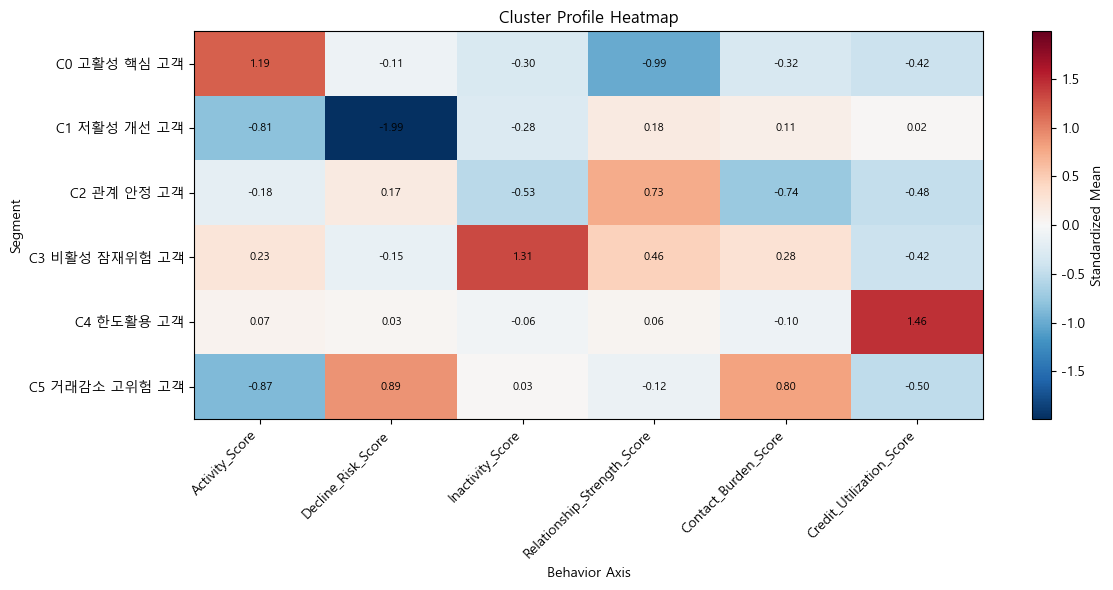

Saved: data\analysis\segment_profiling\01_cluster_profile_heatmap.png


In [14]:
# ============================================================
# 7. Cluster Profile Heatmap
# ============================================================

heatmap_data = axis_profile[features_for_model].values
row_labels = axis_profile["Segment"].astype(str).tolist()
col_labels = features_for_model

abs_max = max(abs(heatmap_data.min()), abs(heatmap_data.max()))

plt.figure(figsize=(12, 6))
plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-abs_max,
    vmax=abs_max,
)
plt.colorbar(label="Standardized Mean")
plt.xticks(ticks=np.arange(len(col_labels)), labels=col_labels, rotation=45, ha="right")
plt.yticks(ticks=np.arange(len(row_labels)), labels=row_labels)
plt.title("Cluster Profile Heatmap")
plt.xlabel("Behavior Axis")
plt.ylabel("Segment")

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        plt.text(j, i, f"{heatmap_data[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
heatmap_path = OUTPUT_DIR / "01_cluster_profile_heatmap.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", heatmap_path.relative_to(ROOT))

## 8. Segment별 이탈률 Bar Chart

행동 기반으로 만든 segment가 실제 이탈률에서도 차이를 보이는지 확인한다. 전체 이탈률 기준선을 함께 표시하여 어떤 segment가 평균보다 위험한지 비교한다.

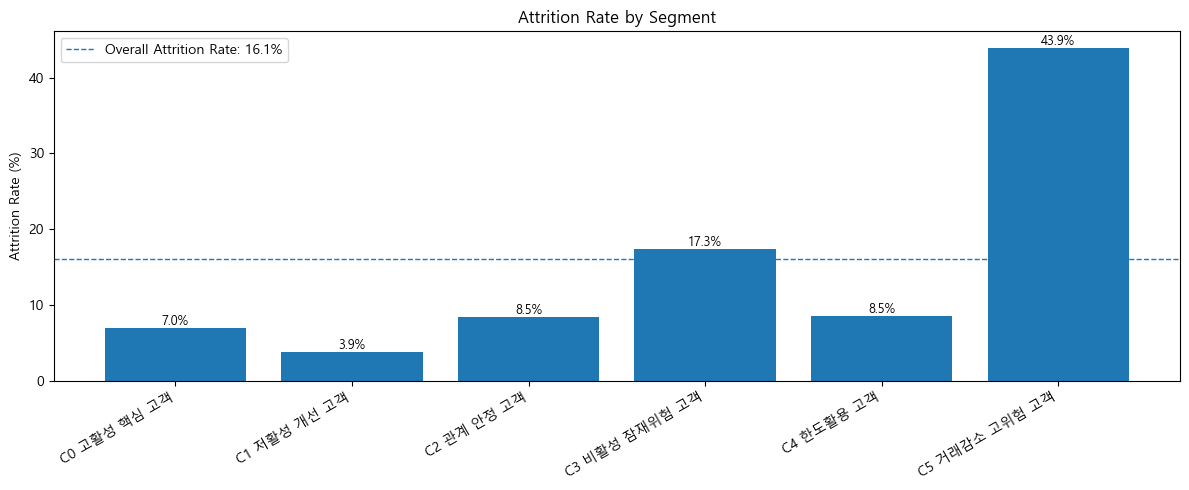

Saved: data\analysis\segment_profiling\02_attrition_rate_by_segment.png


In [15]:
# ============================================================
# 8. Segment별 이탈률 Bar Chart
# ============================================================

if "attrition_rate_percent" in segment_profile.columns:
    plot_df = segment_profile.sort_values("Cluster").copy()

    plt.figure(figsize=(12, 5))
    bars = plt.bar(plot_df["Segment"].astype(str), plot_df["attrition_rate_percent"])

    overall_attrition_percent = overall_attrition_rate * 100
    plt.axhline(
        overall_attrition_percent,
        linestyle="--",
        linewidth=1,
        label=f"Overall Attrition Rate: {overall_attrition_percent:.1f}%",
    )
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Attrition Rate (%)")
    plt.title("Attrition Rate by Segment")
    plt.legend()

    for bar, value in zip(bars, plot_df["attrition_rate_percent"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.tight_layout()
    attrition_path = OUTPUT_DIR / "02_attrition_rate_by_segment.png"
    plt.savefig(attrition_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", attrition_path.relative_to(ROOT))
else:
    print("attrition_rate_percent 컬럼이 없어 이탈률 그래프를 생성하지 않았습니다.")

## 9. Segment Size vs Attrition Rate Bubble Chart

Segment의 고객 수와 이탈률을 동시에 보여준다. 발표에서는 어떤 segment를 우선 관리해야 하는지 설명하는 데 사용할 수 있다.

In [16]:
# ============================================================
# 9. Segment Size vs Attrition Rate Bubble Chart
# ============================================================

if {"n_customers", "attrition_rate_percent"}.issubset(segment_profile.columns):
    bubble_df = segment_profile.copy()
    size_col = "mean_total_trans_amt" if "mean_total_trans_amt" in bubble_df.columns else "n_customers"

    fig = px.scatter(
        bubble_df,
        x="n_customers",
        y="attrition_rate_percent",
        size=size_col,
        color="Segment",
        hover_data=[
            c for c in [
                "Cluster",
                "n_customers",
                "cluster_ratio_percent",
                "attrition_rate_percent",
                "risk_level",
                "strategy_priority",
                "mean_total_trans_ct",
                "mean_total_trans_amt",
                "mean_high_risk_signal_count",
            ] if c in bubble_df.columns
        ],
        labels={
            "n_customers": "Segment Size",
            "attrition_rate_percent": "Attrition Rate (%)",
            size_col: size_col,
        },
        title="Segment Size vs Attrition Rate",
        size_max=60,
    )

    fig.add_hline(
        y=overall_attrition_rate * 100,
        line_dash="dash",
        annotation_text="Overall Attrition Rate",
        annotation_position="top left",
    )
    fig.update_layout(**get_plotly_layout())
    fig.show()

    bubble_path = OUTPUT_DIR / "03_segment_size_vs_attrition_bubble.html"
    fig.write_html(bubble_path)
    print("Saved:", bubble_path.relative_to(ROOT))
else:
    print("필수 컬럼이 없어 bubble chart를 생성하지 않았습니다.")

Saved: data\analysis\segment_profiling\03_segment_size_vs_attrition_bubble.html


## 10. High-risk Signal Overlap 분석

Step 3.5에서 만든 high-risk signal들이 각 segment에 얼마나 많이 포함되어 있는지 확인한다. 이 분석은 clustering 결과의 타당성을 보강하는 데 사용한다.

,Cluster,Segment,High_Inactive_Flag,Low_Ct_Change_Flag,Low_Amt_Change_Flag,High_Contact_Flag,Low_Relationship_Flag,Low_Utilization_Flag,High_Risk_Signal_Count
0,0,C0 고활성 핵심 고객,0.324227,0.059794,0.082474,0.366495,0.636082,0.255670,1.724742
1,1,C1 저활성 개선 고객,0.327273,0.014773,0.014773,0.539773,0.047727,0.140909,1.085227
2,2,C2 관계 안정 고객,0.197299,0.211392,0.230769,0.167352,0.027598,0.325895,1.160305
3,3,C3 비활성 잠재위험 고객,0.984772,0.087745,0.128354,0.616389,0.101523,0.350254,2.269036
4,4,C4 한도활용 고객,0.450385,0.142275,0.169914,0.458994,0.151337,0.000000,1.372904
5,5,C5 거래감소 고위험 고객,0.484638,0.549058,0.452428,0.826561,0.176412,0.402379,2.891477


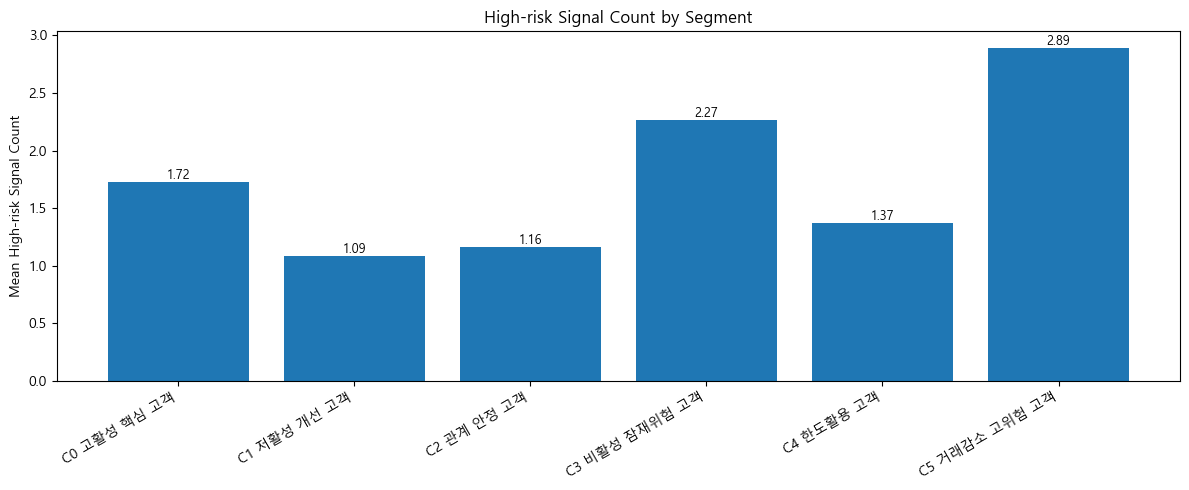

Saved: data\analysis\segment_profiling\high_risk_signal_summary.csv
Saved: data\analysis\segment_profiling\04_high_risk_signal_by_segment.png


In [17]:
# ============================================================
# 10. High-risk Signal Overlap 분석
# ============================================================

risk_signal_cols = [
    "High_Inactive_Flag",
    "Low_Ct_Change_Flag",
    "Low_Amt_Change_Flag",
    "High_Contact_Flag",
    "Low_Relationship_Flag",
    "Low_Utilization_Flag",
]
risk_signal_cols = [c for c in risk_signal_cols if c in df_vis.columns]

if len(risk_signal_cols) > 0 and "High_Risk_Signal_Count" in df_vis.columns:
    risk_summary = (
        df_vis.groupby(["Cluster", "Segment"], observed=True)[risk_signal_cols + ["High_Risk_Signal_Count"]]
        .mean()
        .reset_index()
        .sort_values("Cluster")
    )

    risk_summary_path = OUTPUT_DIR / "high_risk_signal_summary.csv"
    save_csv(risk_summary, risk_summary_path)
    display(risk_summary)

    plt.figure(figsize=(12, 5))
    bars = plt.bar(risk_summary["Segment"].astype(str), risk_summary["High_Risk_Signal_Count"])
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Mean High-risk Signal Count")
    plt.title("High-risk Signal Count by Segment")

    for bar, value in zip(bars, risk_summary["High_Risk_Signal_Count"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.tight_layout()
    risk_plot_path = OUTPUT_DIR / "04_high_risk_signal_by_segment.png"
    plt.savefig(risk_plot_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", risk_summary_path.relative_to(ROOT))
    print("Saved:", risk_plot_path.relative_to(ROOT))
else:
    print("risk signal 컬럼이 없어 high-risk signal 분석을 건너뜁니다.")

## 11. 범주형 변수 분포 분석

Segment별 카드 등급, 소득 구간, 성별, 교육 수준 등의 분포를 확인한다. 이 변수들은 clustering input으로 사용하지 않았으므로, segment의 사후 해석에만 사용한다.

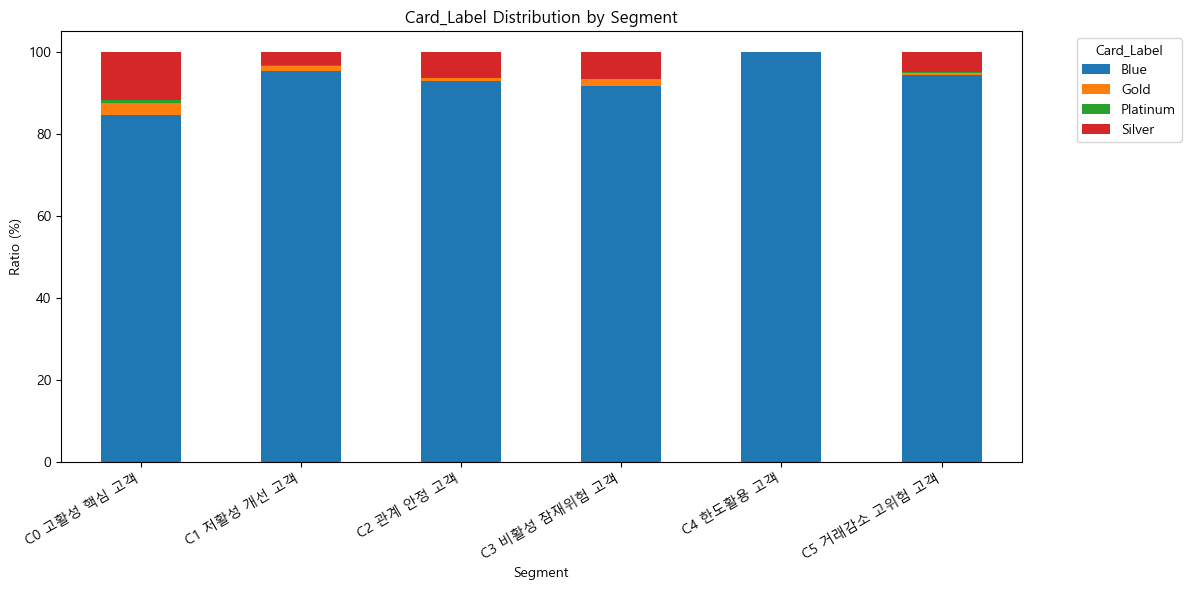

Saved: data\analysis\segment_profiling\05_Card_Label_distribution_by_segment.png
Saved: data\analysis\segment_profiling\05_Card_Label_distribution_by_segment.csv


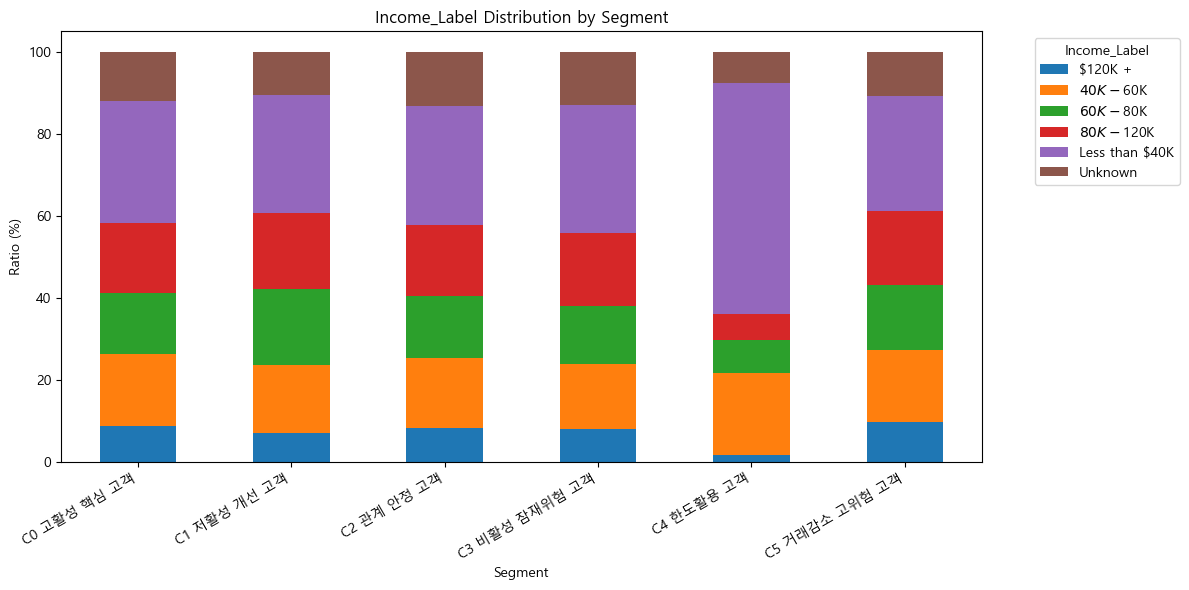

Saved: data\analysis\segment_profiling\05_Income_Label_distribution_by_segment.png
Saved: data\analysis\segment_profiling\05_Income_Label_distribution_by_segment.csv


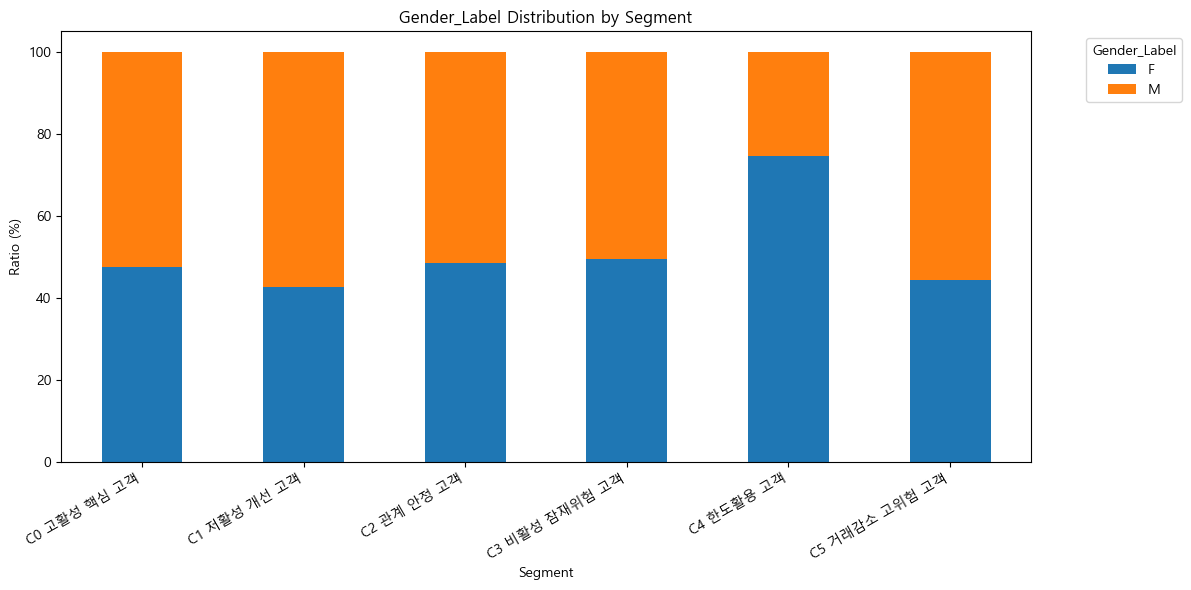

Saved: data\analysis\segment_profiling\05_Gender_Label_distribution_by_segment.png
Saved: data\analysis\segment_profiling\05_Gender_Label_distribution_by_segment.csv


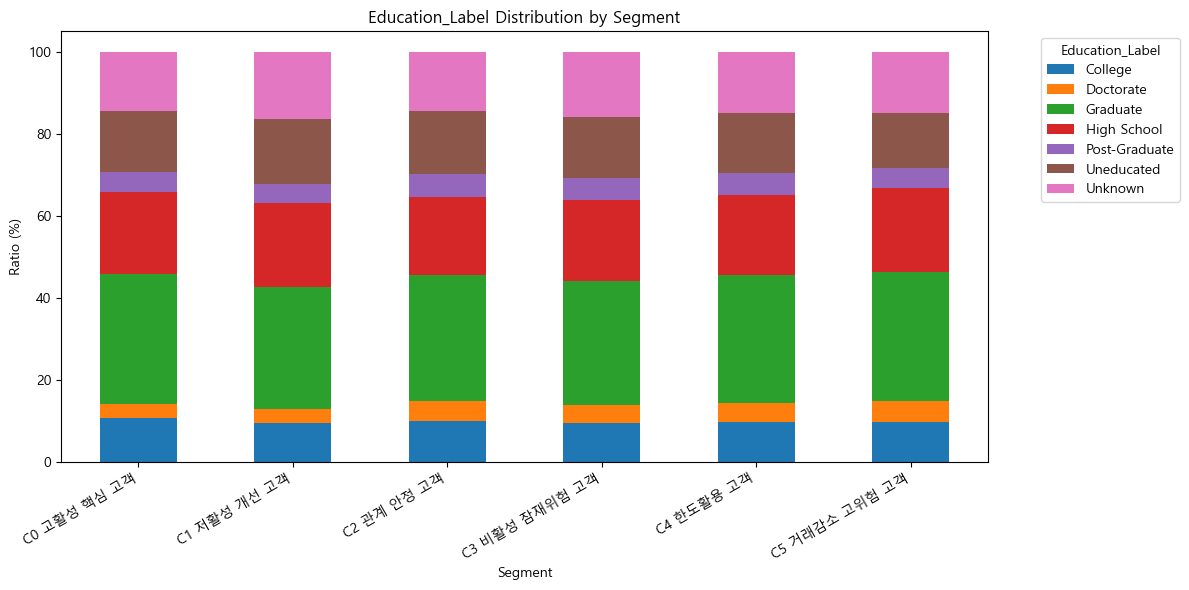

Saved: data\analysis\segment_profiling\05_Education_Label_distribution_by_segment.png
Saved: data\analysis\segment_profiling\05_Education_Label_distribution_by_segment.csv


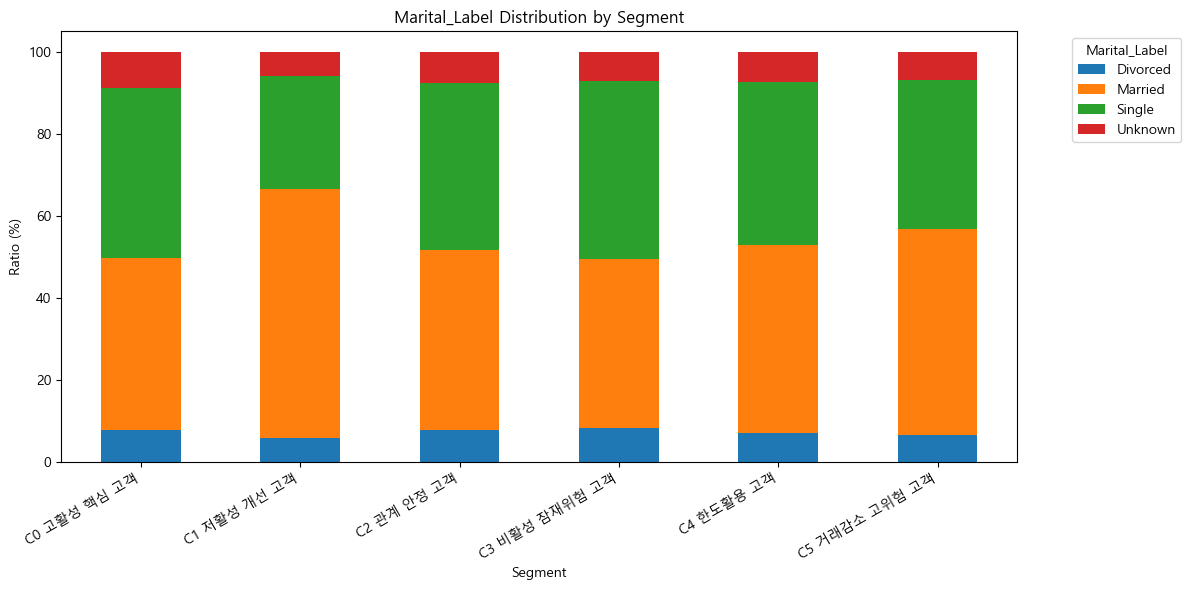

Saved: data\analysis\segment_profiling\05_Marital_Label_distribution_by_segment.png
Saved: data\analysis\segment_profiling\05_Marital_Label_distribution_by_segment.csv
Saved: data\analysis\segment_profiling\categorical_distribution_long.csv


,variable,Segment,category,ratio_percent
0,Card_Label,C0 고활성 핵심 고객,Blue,84.587629
1,Card_Label,C1 저활성 개선 고객,Blue,95.454545
2,Card_Label,C2 관계 안정 고객,Blue,92.836171
3,Card_Label,C3 비활성 잠재위험 고객,Blue,91.733140
4,Card_Label,C4 한도활용 고객,Blue,100.000000


In [18]:
# ============================================================
# 11. 범주형 변수 분포 분석
# ============================================================

categorical_cols = [
    "Card_Label",
    "Income_Label",
    "Gender_Label",
    "Education_Label",
    "Marital_Label",
]
categorical_cols = [c for c in categorical_cols if c in df_vis.columns]

categorical_distribution_rows = []

for category_col in categorical_cols:
    ct = pd.crosstab(df_vis["Segment"], df_vis[category_col], normalize="index") * 100
    ct = ct.reindex(segment_order)

    ct_long = ct.reset_index().melt(
        id_vars="Segment",
        var_name="category",
        value_name="ratio_percent",
    )
    ct_long["variable"] = category_col
    categorical_distribution_rows.append(ct_long)

    ax = ct.plot(kind="bar", stacked=True, figsize=(12, 6))
    plt.ylabel("Ratio (%)")
    plt.title(f"{category_col} Distribution by Segment")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title=category_col, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    plot_path = OUTPUT_DIR / f"05_{category_col}_distribution_by_segment.png"
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()

    csv_path = OUTPUT_DIR / f"05_{category_col}_distribution_by_segment.csv"
    save_csv(ct.reset_index(), csv_path)

    print("Saved:", plot_path.relative_to(ROOT))
    print("Saved:", csv_path.relative_to(ROOT))

if categorical_distribution_rows:
    categorical_distribution_long = pd.concat(categorical_distribution_rows, ignore_index=True)
    categorical_distribution_long = categorical_distribution_long[["variable", "Segment", "category", "ratio_percent"]]
    cat_long_path = OUTPUT_DIR / "categorical_distribution_long.csv"
    save_csv(categorical_distribution_long, cat_long_path)
    print("Saved:", cat_long_path.relative_to(ROOT))
    display(categorical_distribution_long.head())
else:
    print("사용 가능한 범주형 label 컬럼이 없습니다.")

## 12. 최종 해석용 통합 테이블 저장

개별 고객 단위로 cluster와 segment label이 붙은 테이블을 저장한다. 이후 classification 단계나 추가 분석에서 사용할 수 있다.

In [19]:
# ============================================================
# 12. 최종 해석용 통합 테이블 저장
# ============================================================

final_table_path = OUTPUT_DIR / "profile_table_with_segment.csv"
save_csv(df_vis, final_table_path)

print("Saved:", final_table_path.relative_to(ROOT))
print("Final table shape:", df_vis.shape)

Saved: data\analysis\segment_profiling\profile_table_with_segment.csv
Final table shape: (10127, 65)


## 13. Step 5 README 및 실행 metadata 저장

이 단계에서 생성된 파일의 역할을 설명하는 README와 실행 metadata를 저장한다.

In [20]:
# ============================================================
# 13. Step 5 README 및 실행 metadata 저장
# ============================================================

metadata = {
    "step": "Step 5 Segment Profiling & Strategy",
    "selected_model": selected_model,
    "selected_key": selected_key,
    "label_column": label_col,
    "features_for_model": features_for_model,
    "n_rows": int(len(df_vis)),
    "n_clusters": int(df_vis["Cluster"].nunique()),
    "overall_attrition_rate": float(overall_attrition_rate) if not pd.isna(overall_attrition_rate) else None,
    "segment_name_map": {str(k): v for k, v in SEGMENT_NAME_MAP.items()},
    "output_files": [
        "cluster_axis_profile_mean.csv",
        "final_segment_profiling_table.csv",
        "segment_strategy_table.csv",
        "01_cluster_profile_heatmap.png",
        "02_attrition_rate_by_segment.png",
        "03_segment_size_vs_attrition_bubble.html",
        "04_high_risk_signal_by_segment.png",
        "categorical_distribution_long.csv",
        "profile_table_with_segment.csv",
    ],
}
metadata_path = OUTPUT_DIR / "00_segment_profiling_run_metadata.json"
save_json(metadata, metadata_path)

readme_text = f"""# Step 5. Segment Profiling & Strategy

## 목적

Step 4에서 선택한 최종 clustering 결과를 기반으로 각 고객 세그먼트의 행동 특성, 이탈률, 고위험 신호, 고객 속성 분포를 해석하고 카드사 관점의 유지·재활성화 전략을 제안한다.

## 선택 모델

- Selected key: `{selected_key}`
- Number of clusters: `{df_vis["Cluster"].nunique()}`
- Overall attrition rate: `{overall_attrition_rate:.4f}`

## 입력 파일

- `data/analysis/clustering_results/09_selected_model.json`
- `data/analysis/clustering_results/10_selected_cluster_labels.csv`
- `data/analysis/clustering_results/11_df_cluster_input_used.csv`
- `data/analysis/clustering_results/12_df_profile_table_used.csv`

## 주요 출력 파일

| 파일 | 설명 |
|---|---|
| `cluster_axis_profile_mean.csv` | segment별 행동 축 평균 |
| `final_segment_profiling_table.csv` | segment별 고객 수, 이탈률, 주요 행동 변수, 위험 수준 요약 |
| `segment_strategy_table.csv` | segment별 해석과 유지·재활성화 전략 |
| `01_cluster_profile_heatmap.png` | 행동 축 기반 segment profile heatmap |
| `02_attrition_rate_by_segment.png` | segment별 이탈률 비교 그래프 |
| `03_segment_size_vs_attrition_bubble.html` | segment 규모와 이탈률 bubble chart |
| `04_high_risk_signal_by_segment.png` | segment별 high-risk signal 평균 |
| `categorical_distribution_long.csv` | segment별 범주형 변수 분포 long table |
| `profile_table_with_segment.csv` | 고객 단위 profile table에 cluster/segment label을 붙인 최종 테이블 |

## 해석 주의사항

- `Attrition_Flag`는 clustering input에 사용하지 않았고, segment별 이탈률을 사후적으로 비교하기 위해서만 사용하였다.
- 성별, 소득, 카드 등급, 교육 수준 등 범주형 label은 clustering input에 사용하지 않았고, segment profiling 단계에서만 사용하였다.
- 2D/3D 투영 시각화에서 군집이 완전히 분리되지 않더라도, 본 분석의 핵심 해석은 cluster profile heatmap, segment별 이탈률, high-risk signal 차이를 중심으로 수행한다.
"""

readme_path = OUTPUT_DIR / "README_segment_profiling.md"
readme_path.write_text(readme_text, encoding="utf-8")

print("Saved:", metadata_path.relative_to(ROOT))
print("Saved:", readme_path.relative_to(ROOT))

Saved: data\analysis\segment_profiling\00_segment_profiling_run_metadata.json
Saved: data\analysis\segment_profiling\README_segment_profiling.md


## 14. 결과 파일 압축 선택

제출이나 공유가 필요할 경우, Step 5 결과 폴더를 `outputs/` 아래 ZIP으로 압축할 수 있다.

In [21]:
# ============================================================
# 14. 결과 파일 압축 선택
# ============================================================

zip_output_dir = ROOT / "outputs"
zip_output_dir.mkdir(parents=True, exist_ok=True)

zip_base = zip_output_dir / "step5_segment_profiling_results"
zip_path = shutil.make_archive(base_name=str(zip_base), format="zip", root_dir=OUTPUT_DIR)

print("Created ZIP:", Path(zip_path).relative_to(ROOT))

Created ZIP: outputs\step5_segment_profiling_results.zip
